# RFMiD — búsqueda de hiperparámetros con Optuna (ResNet-152, Disease_Risk)

**Objetivo:** maximizar el **AUC de validación**.

**Sin fuga de datos:** cada trial ajusta los pesos con *train* y se puntúa **solo con *validación***. El conjunto de *test* no se carga en ningún momento de este notebook (`src/tuning.py` no lo lee); queda reservado para la evaluación final en `02.1_train_resnet152.ipynb`.

## Presupuesto de cómputo (régimen reducido)

Esta máquina **no tiene GPU** (solo CPU, 4 hilos). Medido: una pasada forward+backward de 16 imágenes a 224 px cuesta ~3.1 s con `layer4` entrenable y ~6.6 s con `layer3+layer4`, es decir, ~11 min por época completa (train + val) a 224 px. Entrenar 20 épocas por trial es inviable, así que **cada trial usa un régimen reducido**:

| Ajuste | Valor | Motivo |
|---|---|---|
| Tamaño de imagen | 160 px (el final usa 224) | ~2x más rápido |
| Train | 50 % estratificado (960 imgs) | ~2x más rápido, mantiene la proporción de clases |
| Validación | completa (640 imgs) | el AUC con pocos negativos es ruidoso; no se recorta |
| Épocas por trial | 4 | suficiente para ordenar configuraciones; lo prolongado lo decide el entrenamiento final |
| Nº de trials | 12 | ~2 h de CPU |

Las imágenes se reescalan una sola vez y se guardan en RAM (evita decodificar PNGs de 2144x1424 en cada época). **Caveat:** el óptimo en este régimen corto/pequeño puede favorecer LR altos y convergencia rápida; es una guía, no el óptimo del entrenamiento completo.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

# Localiza retina_clasificacion/ aunque el cwd del kernel sea el padre Retina/
_cwd = Path.cwd().resolve()
_candidates = [_cwd, *_cwd.parents]
if _cwd.is_dir():
    _candidates.extend(sorted(path for path in _cwd.iterdir() if path.is_dir()))
PROJECT_ROOT = next(
    directory
    for directory in _candidates
    if (directory / "src" / "config.py").is_file() and (directory / "requirements.txt").is_file()
)
sys.path = [entry for entry in sys.path if Path(entry or ".").resolve() != PROJECT_ROOT]
sys.path.insert(0, str(PROJECT_ROOT))
os.environ.setdefault("TORCH_HOME", str(PROJECT_ROOT / "artifacts" / "torch_cache"))

import matplotlib.pyplot as plt
import optuna

from src.config import default_config
from src.train import get_device
from src.tuning import (
    BASELINE_PARAMS,
    build_tuning_data,
    count_finished_trials,
    create_objective,
    trials_to_dataframe,
)

base_config = default_config()
print(f"device={get_device()} | optuna={optuna.__version__}")

C:\Users\Xabat Arin\miniconda3\envs\dl\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device=cpu | optuna=5.0.0


## Espacio de búsqueda y justificación

| Hiperparámetro | Rango | Por qué |
|---|---|---|
| `learning_rate` | 1e-5 … 1e-3 (log) | El baseline usa 1e-4; la escala es multiplicativa, de ahí la búsqueda logarítmica. |
| `weight_decay` | 1e-6 … 1e-2 (log) | Regularización de AdamW; con ~2k imágenes y `layer4` (~15 M parámetros) el sobreajuste es el riesgo principal. |
| `focal_gamma` | 1.0 … 3.0 | Cuánto se ignoran los ejemplos fáciles; 2.0 es el valor estándar, se explora a ambos lados. |
| `focal_alpha` | 0.15 … 0.75 | Peso de la clase **positiva** (Disease_Risk=1, ~79 % de los datos). Un peso balanceado por frecuencia inversa sería ≈ 0.21 (el baseline 0.25 ya está ahí), pero el AUC no depende de un umbral y a veces gana pesar más la clase mayoritaria, así que se explora hacia arriba. |
| `batch_size` | 8 / 16 / 32 | Ruido del gradiente vs. estabilidad de BatchNorm; lotes pequeños dan más actualizaciones por época. |
| `unfreeze_layer3` | False / True | Más capacidad de adaptación al dominio de fondo de ojo (imágenes muy distintas de ImageNet) a cambio de coste y más riesgo de sobreajuste. |
| `lr_scheduler` | none / cosine / plateau | `none` = baseline; `cosine` decae suavemente; `plateau` reduce el LR a la mitad si el AUC se estanca 2 épocas. |

**Excluido:** la fuerza de *data augmentation*. Con un 50 % de train y 4 épocas su efecto no se puede medir de forma fiable, y se mantiene la augmentation del baseline.

**Sampler / pruner:** `TPESampler(seed=42)` (reproducible) y `MedianPruner` con `trial.report` del AUC de validación tras cada época (3 trials de arranque sin podar y sin podar la primera época). El primer trial es **el baseline** (`enqueue_trial`), para tener una referencia en el mismo régimen reducido.

In [2]:
IMAGE_SIZE = 160
TRAIN_FRACTION = 0.5
EPOCHS_PER_TRIAL = 4
N_TRIALS = 12
TIMEOUT_SECONDS = 3 * 3600  # red de seguridad: no lanza trials nuevos pasado este tiempo

start = time.time()
tuning_data = build_tuning_data(base_config, image_size=IMAGE_SIZE, train_fraction=TRAIN_FRACTION)
print(
    f"train={len(tuning_data.train_dataset)} imgs, val={len(tuning_data.val_dataset)} imgs, "
    f"cache en {time.time() - start:.0f}s"
)

train=960 imgs, val=640 imgs, cache en 160s


In [3]:
optuna_dir = PROJECT_ROOT / "artifacts" / "optuna"
optuna_dir.mkdir(parents=True, exist_ok=True)
storage_url = f"sqlite:///{(optuna_dir / 'study.db').as_posix()}"

study = optuna.create_study(
    study_name="resnet152_disease_risk",
    storage=storage_url,
    load_if_exists=True,  # reanudable: si se interrumpe, volver a ejecutar continúa el estudio
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=1),
)
if len(study.trials) == 0:
    study.enqueue_trial(BASELINE_PARAMS)  # trial 0 = configuración del baseline

remaining_trials = N_TRIALS - count_finished_trials(study)
print(f"Trials terminados: {count_finished_trials(study)} | pendientes: {remaining_trials}")

optimization_start = time.time()
if remaining_trials > 0:
    study.optimize(
        create_objective(tuning_data, base_config, EPOCHS_PER_TRIAL),
        n_trials=remaining_trials,
        timeout=TIMEOUT_SECONDS,
    )
print(f"Optimización: {(time.time() - optimization_start) / 60:.1f} min en esta ejecución")

[I 2026-10-05 07:25:49,811] A new study created in RDB with name: resnet152_disease_risk


Trials terminados: 0 | pendientes: 12


[trial 0] epoch 1/4 | train_loss=0.0450 | val_loss=0.0704 | val_auc=0.8618


[trial 0] epoch 2/4 | train_loss=0.0403 | val_loss=0.0311 | val_auc=0.9230


[trial 0] epoch 3/4 | train_loss=0.0343 | val_loss=0.0402 | val_auc=0.9415


...

[trial 10] epoch 3/4 | train_loss=0.0546 | val_loss=0.0498 | val_auc=0.9412


[trial 11] epoch 1/4 | train_loss=0.0563 | val_loss=0.0419 | val_auc=0.9179


[trial 11] epoch 2/4 | train_loss=0.0455 | val_loss=0.0389 | val_auc=0.9311


[I 2026-10-05 09:47:00,980] Trial 11 pruned. 


[trial 11] epoch 3/4 | train_loss=0.0421 | val_loss=0.0372 | val_auc=0.9331
Optimización: 141.2 min en esta ejecución


## Resultados

In [4]:
print(f"Mejor trial: #{study.best_trial.number}")
print(f"Mejor AUC de validación (régimen reducido): {study.best_value:.4f}")
print("Mejores hiperparámetros:")
for name, value in study.best_params.items():
    print(f"  {name}: {value}")

trials_table = trials_to_dataframe(study)
trials_table

Mejor trial: #2
Mejor AUC de validación (régimen reducido): 0.9432
Mejores hiperparámetros:
  learning_rate: 0.000462258900102083
  weight_decay: 7.068974950624607e-06
  focal_gamma: 1.3636499344142012
  focal_alpha: 0.2600427059120603
  batch_size: 16
  unfreeze_layer3: True
  lr_scheduler: plateau


,number,value,state,duration,batch_size,focal_alpha,focal_gamma,learning_rate,lr_scheduler,unfreeze_layer3,weight_decay
0,0,0.941478,COMPLETE,0 days 00:11:20.867241,16,0.250000,2.000000,0.000100,none,False,0.000100
1,1,0.931361,COMPLETE,0 days 00:11:55.557711,8,0.509195,2.463988,0.000056,plateau,False,0.006351
2,2,0.943174,COMPLETE,0 days 00:19:04.350126,16,0.260043,1.363650,0.000462,plateau,True,0.000007
3,3,0.937039,PRUNED,0 days 00:08:09.045240,32,0.458541,1.399348,0.000082,cosine,False,0.001383
4,4,0.940048,PRUNED,0 days 00:08:25.448997,16,0.414091,2.368466,0.000041,none,False,0.000002
5,5,0.845938,PRUNED,0 days 00:09:02.868526,8,0.615080,2.939169,0.000124,plateau,False,0.000005
6,6,0.942761,COMPLETE,0 days 00:11:15.690019,16,0.364052,2.657475,0.000060,none,False,0.000012
7,7,0.936833,PRUNED,0 days 00:15:11.268284,8,0.587404,2.413715,0.000010,none,True,0.001827
8,8,0.909578,PRUNED,0 days 00:10:05.457756,8,0.532534,2.459212,0.000042,cosine,True,0.000020
9,9,0.936597,PRUNED,0 days 00:13:58.177143,16,0.214735,1.050838,0.000111,plateau,True,0.000051


C:\Users\Xabat Arin\AppData\Local\Temp\ipykernel_16760\3959657139.py:3: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study)


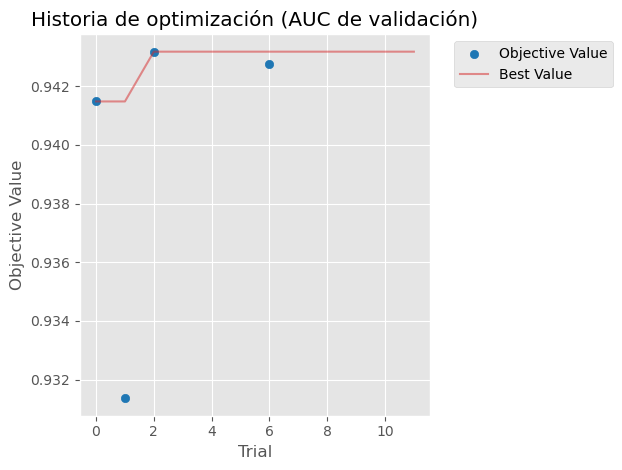

Pocos trials completados para estimar importancias.


In [5]:
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

plot_optimization_history(study)
plt.title("Historia de optimización (AUC de validación)")
plt.tight_layout()
plt.savefig(optuna_dir / "optimization_history.png", dpi=110)
plt.show()

completed_trials = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
if len(completed_trials) >= 5:
    plot_param_importances(study)
    plt.title("Importancia de hiperparámetros")
    plt.tight_layout()
    plt.savefig(optuna_dir / "param_importances.png", dpi=110)
    plt.show()
else:
    print("Pocos trials completados para estimar importancias.")

In [6]:
best_params_path = optuna_dir / "best_params.json"
payload = {
    "best_params": study.best_params,
    "best_val_auc_reduced_regime": study.best_value,
    "best_trial_number": study.best_trial.number,
    "search_regime": {
        "image_size": IMAGE_SIZE,
        "train_fraction": TRAIN_FRACTION,
        "epochs_per_trial": EPOCHS_PER_TRIAL,
        "n_trials": N_TRIALS,
    },
}
best_params_path.write_text(json.dumps(payload, indent=2), encoding="utf-8")
print(f"Guardado en {best_params_path}")

Guardado en C:\Users\Xabat Arin\Desktop\kaggle\Retina\artifacts\optuna\best_params.json


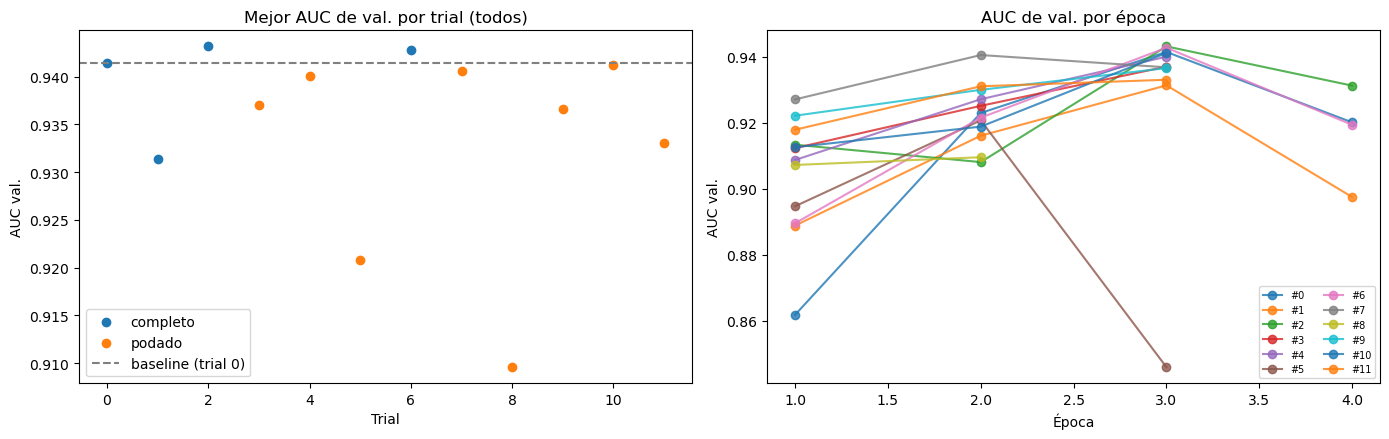

In [2]:
# Optuna solo dibuja los trials COMPLETOS; aquí se muestran todos usando el mejor AUC
# de validación que alcanzó cada trial antes de terminar o ser podado.
trial_best_auc = {
    t.number: max(t.intermediate_values.values())
    for t in study.trials
    if t.intermediate_values
}
baseline_auc = trial_best_auc[0]

figure, (history_axis, curves_axis) = plt.subplots(1, 2, figsize=(14, 4.5))
for trial in study.trials:
    is_complete = trial.state == optuna.trial.TrialState.COMPLETE
    history_axis.scatter(
        trial.number,
        trial_best_auc[trial.number],
        color="tab:blue" if is_complete else "tab:orange",
        label="completo" if is_complete else "podado",
    )
    steps, values = zip(*sorted(trial.intermediate_values.items()))
    curves_axis.plot(steps, values, marker="o", alpha=0.8, label=f"#{trial.number}")
history_axis.axhline(baseline_auc, color="gray", linestyle="--", label="baseline (trial 0)")
handles, labels = history_axis.get_legend_handles_labels()
unique = dict(zip(labels, handles))
history_axis.legend(unique.values(), unique.keys())
history_axis.set(title="Mejor AUC de val. por trial (todos)", xlabel="Trial", ylabel="AUC val.")
curves_axis.set(title="AUC de val. por época", xlabel="Época", ylabel="AUC val.")
curves_axis.legend(ncol=2, fontsize=7)
plt.tight_layout()
plt.savefig(optuna_dir / "all_trials.png", dpi=110)
plt.show()

### Lectura de resultados

- Se ejecutaron **12 trials** (4 completos, 8 podados) en ~2.4 h de CPU. El **mejor** fue el trial #2: `layer3+layer4` entrenables, LR ≈ 4.6e-4, `ReduceLROnPlateau`, gamma ≈ 1.36, alpha ≈ 0.26, batch 16, weight decay ≈ 7e-6, con AUC de validación 0.9432 en el régimen reducido.
- **La mejora es marginal:** el baseline (trial 0) obtuvo 0.9415 y el resto de trials está en 0.93–0.943. Con 134 negativos en validación la incertidumbre del AUC es del orden de ±0.01, así que **las diferencias entre los mejores trials no son estadísticamente distinguibles**. El espacio es bastante plano alrededor del baseline; lo único consistentemente peor son los trials con **batch 8** (#1, #5, #8: mejor AUC 0.931, 0.921, 0.910; el #5 llegó a caer a 0.846 en la época 3), con curvas más ruidosas.
- Los 4 trials que llegaron a la época 4 (#0, #1, #2, #6) tuvieron su mejor AUC en la época 3 y bajaron en la 4 (ruido y/o sobreajuste con solo 960 imágenes); en el entrenamiento completo, el *early stopping* y la selección del checkpoint por AUC de validación cubren esto.
- **Importancia de hiperparámetros:** Optuna solo la estima con trials completos y aquí hay 4 (insuficientes), por lo que no se calcula.
- El mejor trial descongela `layer3` (≈1.7x más coste por época que el baseline). Se espera, como mucho, una mejora modesta del modelo final sobre el baseline.